# Where Ramen helps and where it hurts: DomainNet (6 domains, 345 classes, ViT-B/32)

For individual test samples this notebook shows
1. **zero-shot vs Ramen probabilities** (orange = zero-shot CLIP, the NoAdapt run; blue = Ramen),
2. **the state of Ramen's memory at that moment**: how many entries, how many queues are full, how many entries are filed under their true class, and the queues of the sample's true class, zero-shot class and Ramen class,
3. **the active set**: the retrieved memory entries behind this sample's update, with their share of the update weight, and that weight summed per class queue.

Two groups of samples:
- **fixed**: zero-shot wrong, Ramen right, drawn from the domain where Ramen gains the most;
- **broken**: zero-shot right, Ramen wrong, drawn from the domain where Ramen does worst (lowest fixed / broken ratio).

Samples are drawn at random with a fixed seed (`RamenExamples.pick`), not hand-picked, and only after the first 20% of the stream so the memory is warm. Section 3 checks whether the patterns in the examples hold over 150 samples per group.

**How the memory is obtained (no GPU, no re-run).** Ramen's memory never depends on its adapted outputs: every sample is written, before retrieval, into the queue of its zero-shot class, with priority = its stream counter (fp16, as in Ramen) and its zero-shot entropy. `ramen_examples.CacheReplay` replays those writes from the class each sample was filed under, logged by `active_prob_T3` (RamenActive with zero-shot class weights). Its *writes* are Ramen's (the selector only changes retrieval), so its `filed_as` log gives Ramen's memory exactly. Its top-8 retrieval log uses the T=3 class weights, so the check below re-applies them (`temperature=3`); the examples use Ramen's own unweighted retrieval. The active set is then recomputed from the NoAdapt run's features and entropies with Ramen's rule (max_capacity 300, topk 10, beta 5: every non-empty class queue contributes its 10 nearest entries, weighted by exp(-H) * exp(-5 d)).

Seed 0, mixed stream. Code: `new_experiments/ramen_examples.py`.

In [1]:
import os
os.environ['CUDA_VISIBLE_DEVICES'] = ''  # everything here is offline; CLIP is only loaded (on CPU) for the dataset objects

import pandas as pd
import matplotlib.pyplot as plt
from ramen_examples import RamenExamples

pd.set_option('display.width', 250)
pd.set_option('display.max_columns', 30)
%matplotlib inline

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
ex = RamenExamples('DomainNet', 'vitbase32', filed_from='active_prob_T3')

DomainNet: 6 domains x 596006 images in total, 345 classes, model=clip_vitbase32, mode=mixed


## 1. Is the replayed memory Ramen's?
200 random stream positions, compared with what the logged run recorded. Differences in the retrieved entries come from the features: the replay uses the NoAdapt run's, Ramen's internal zero-shot pass differs from it in fp16 numerics only (the two runs file 0.2-0.4% of samples under a different class), which can swap near-tied neighbours.

In [3]:
ex.validate(temperature=3.0)

positions checked                    200.0000
top-1 retrieved entry identical %     98.5000
top-8 retrieved overlap %             98.7500
top-1 weight abs. error (median)       0.0001
dtype: float64

## 2. Where Ramen improves and where it fails more
Per domain: accuracy of zero-shot CLIP and Ramen, and the share of samples Ramen fixes (zero-shot wrong, Ramen right) and breaks (zero-shot right, Ramen wrong). `fixed / broken` below 1 would mean Ramen hurts there.

In [4]:
table = ex.domain_table()
improve = table.drop('mean over domains')['gain'].idxmax()
fail = table.drop('mean over domains')['fixed / broken'].idxmin()
print(f'Ramen improves most on: {improve}    fails most (lowest fixed/broken): {fail}')
table

Ramen improves most on: quickdraw    fails most (lowest fixed/broken): real


,samples,zero-shot %,Ramen %,fixed %,broken %,gain,fixed / broken
domain,,,,,,,
quickdraw,172500.0,13.33,17.54,6.10,1.89,4.21,3.23
painting,75759.0,64.58,65.70,2.89,1.78,1.12,1.63
infograph,53201.0,43.90,44.98,2.72,1.64,1.08,1.66
clipart,48833.0,68.25,69.33,3.20,2.12,1.08,1.51
sketch,70386.0,60.05,60.96,3.03,2.12,0.91,1.43
real,175327.0,82.12,82.27,1.46,1.31,0.15,1.11
mean over domains,596006.0,55.37,56.80,3.24,1.81,1.43,1.76


## 3. The memory and the active set behind fixed vs broken samples (150 random samples each)
Columns (all from the replayed memory at the sample's moment in the stream):
- `true-class queue size` / `purity %`: entries in the queue of the sample's true class, and the share of them that truly belong to it;
- `update % from true-class queue` / `from Ramen-class queue`: share of the update weight that comes from those queues;
- `self weight %`: share from the sample itself (it is written before retrieval; 0 once its queue is full and frozen, see the fp16 note below);
- `update % from same domain` vs `memory % from same domain`: share of the update weight from images of the sample's own corruption/domain, against that domain's share of the whole memory (what random retrieval would give);
- `active entries truly of query class %`: update weight on entries whose true class is the sample's true class.

fp16 note: Ramen's priorities are fp16 and become `inf` after 65,519 samples, after which a full queue never accepts a new entry: late in the stream, full queues are frozen.

In [5]:
ex.compare_outcomes(n=150)

,samples,p_true zs,p_true Ramen,true-class queue size,true-class queue purity %,update % from true-class queue,update % from Ramen-class queue,self weight %,update % from same domain,memory % from same domain,active entries truly of query class %
outcome,,,,,,,,,,,
fixed,150,0.15,0.45,296.45,64.16,1.15,1.15,0.05,60.61,17.70,1.49
broken,150,0.33,0.20,297.95,52.00,1.37,1.10,0.09,52.01,18.77,1.58
both right,150,0.79,0.86,294.44,64.13,3.85,3.85,0.66,56.08,25.57,4.05


**What the table says (DomainNet):**
- **The active set is more local than on ImageNet-C** (topk 10, beta 5). The true-class queue supplies 1.2-3.9% of the update weight, 4-13x the uniform 0.29% (1/345). About 52-61% comes from the query's own domain, against 18-26% of the memory.
- **Broken samples are not a wrong-queue takeover.** On average the Ramen-class queue (1.10%) gets *less* weight than the true-class queue (1.37%). As on ImageNet-C, broken samples are low-margin zero-shot hits (p_true 0.33 vs 0.79 for both-right).
- Fixed samples draw more from their own domain than broken ones (61 vs 52%). Fixed samples come mostly from quickdraw, where 17% of the memory gives 61-70% of the weight.
- **Self weight is ~0 and the memory is frozen.** All examples are after 20% of the stream (position > 119k). By then Ramen's fp16 priorities have saturated to inf (after 65,519 samples), so a full queue never accepts a new entry: 325-339 of the 345 queues are full and frozen. The query is never written, and every later query sees the same snapshot. The `mouth` queue below is identical at positions 266,294 and 424,989.

## 4. Examples where Ramen improves (fixed, from the domain with the largest gain)
How to read each figure: top left the query; top middle zero-shot (orange) vs Ramen (blue) probabilities on the true class (bold) and the most likely others; top right the update weight summed per class queue (green = true class, orange = zero-shot class, red = Ramen's class). Second row: the 10 retrieved entries with the largest weight, with the class they were filed under, their share of the update and their domain. Lower rows: the queues of the true class, the zero-shot class and Ramen's class (10 most recent entries, size and purity on the left). Red frame = memory entry filed under a class that is not its true class.

In [6]:
fixed = ex.pick('fixed', domain=improve, n=3)
broken = ex.pick('broken', domain=fail, n=3)
states = ex.state(list(fixed.position) + list(broken.position))
ex.memory_summary(states)

,domain,outcome,true,zero-shot,Ramen,p_true zs,p_true Ramen,true-class queue size,true-class queue purity %,update % from true-class queue,update % from Ramen-class queue,self weight %,update % from same domain,memory % from same domain,active entries truly of query class %
position,,,,,,,,,,,,,,,
176385,quickdraw,fixed,donut,circle,donut,0.14,0.57,300,72.33,1.42,1.42,0.0,68.11,16.55,1.90
266294,quickdraw,fixed,mouth,nose,mouth,0.07,0.24,300,40.67,1.02,1.02,0.0,69.85,16.08,1.35
439052,quickdraw,fixed,chair,ladder,chair,0.06,0.47,300,39.00,0.39,0.39,0.0,69.07,15.97,0.67
240398,real,broken,moustache,moustache,goatee,0.48,0.41,300,54.67,2.16,1.81,0.0,63.90,36.77,2.02
308135,real,broken,shovel,shovel,baseball_bat,0.45,0.14,300,35.00,0.89,0.97,0.0,74.75,36.87,1.17
424989,real,broken,mouth,mouth,lipstick,0.30,0.21,300,40.67,0.93,1.47,0.0,71.34,36.92,1.48


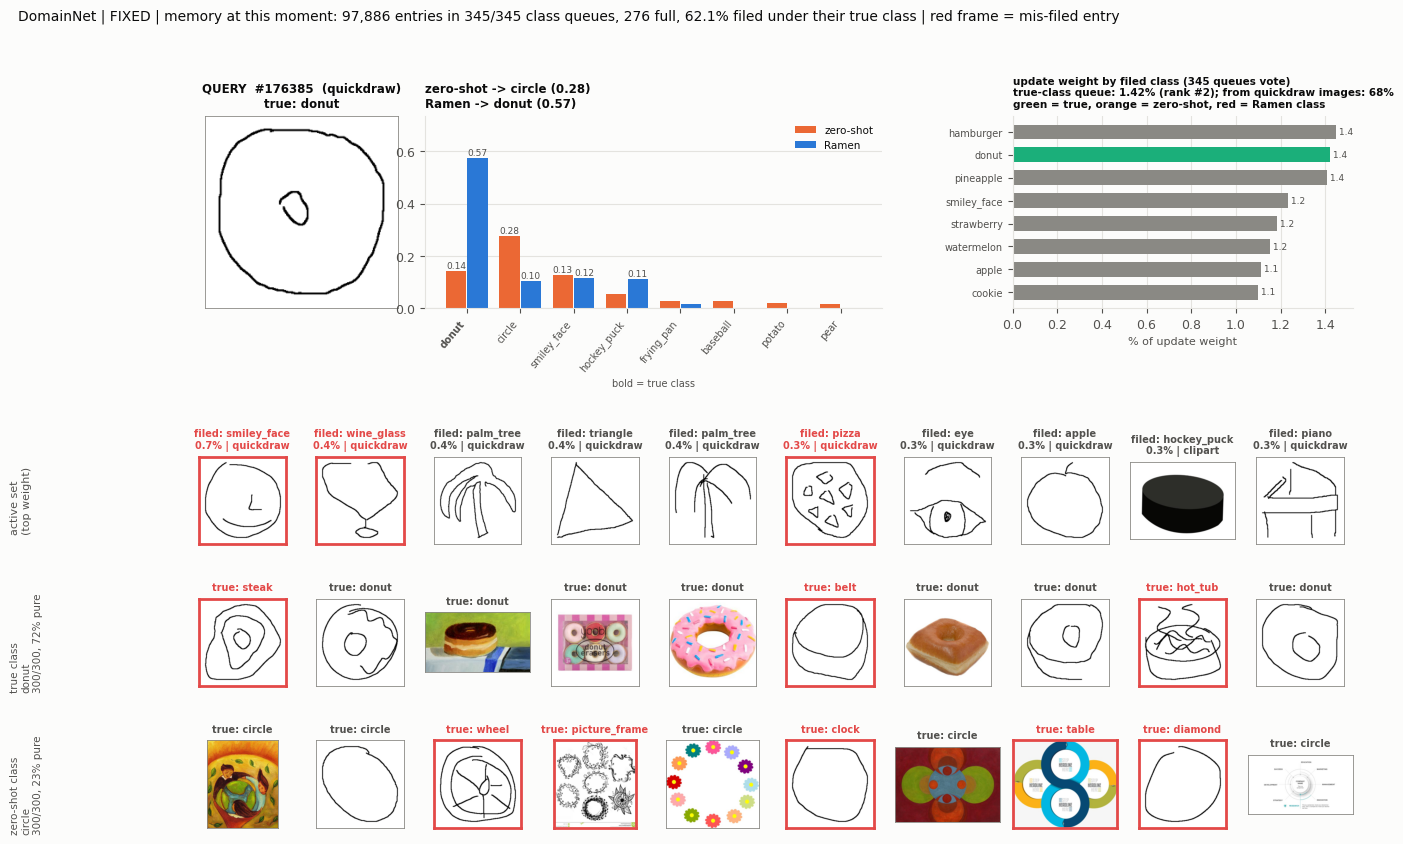

In [7]:
ex.show(fixed.position.iloc[0], states);

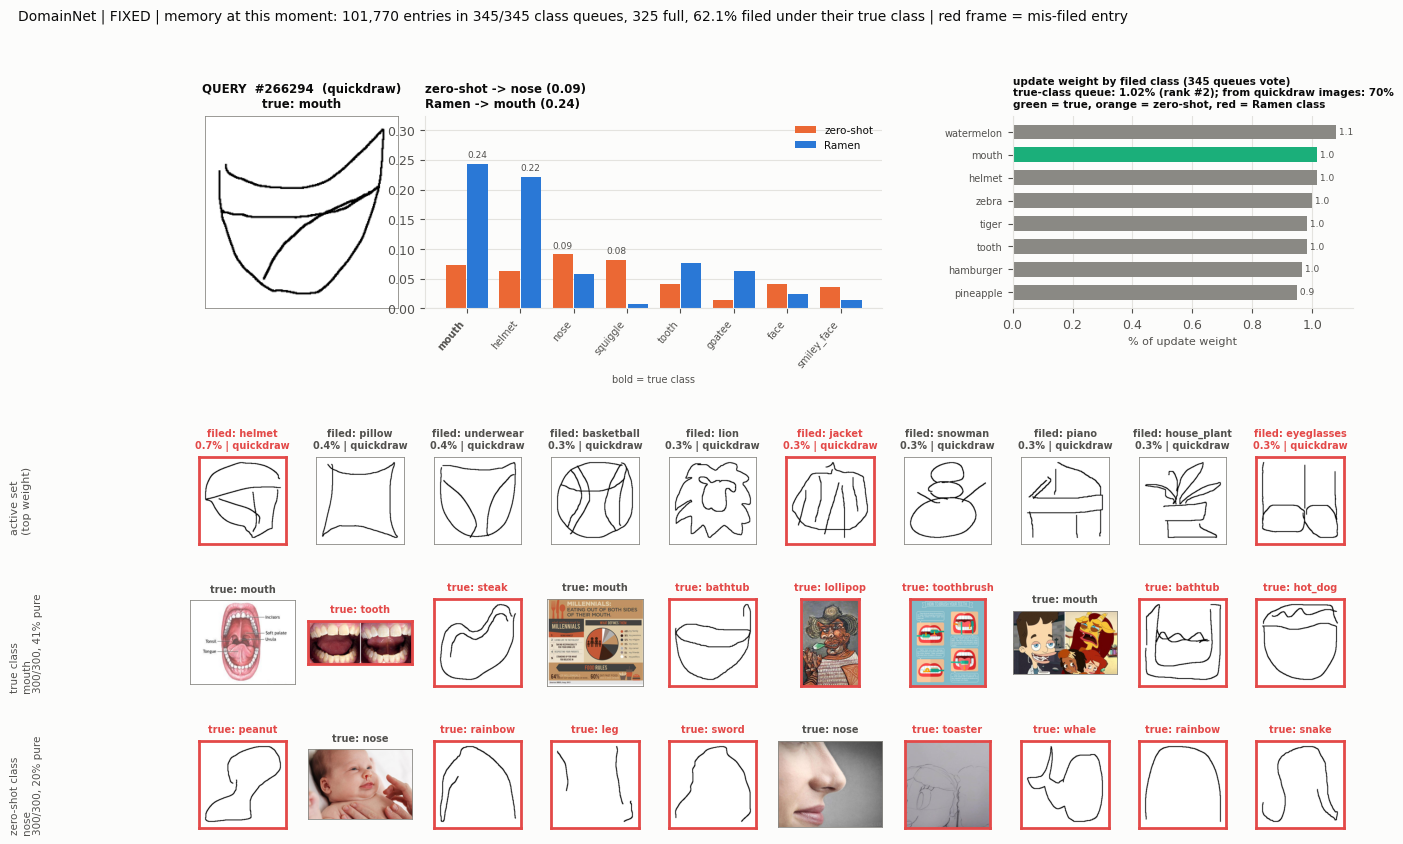

In [8]:
ex.show(fixed.position.iloc[1], states);

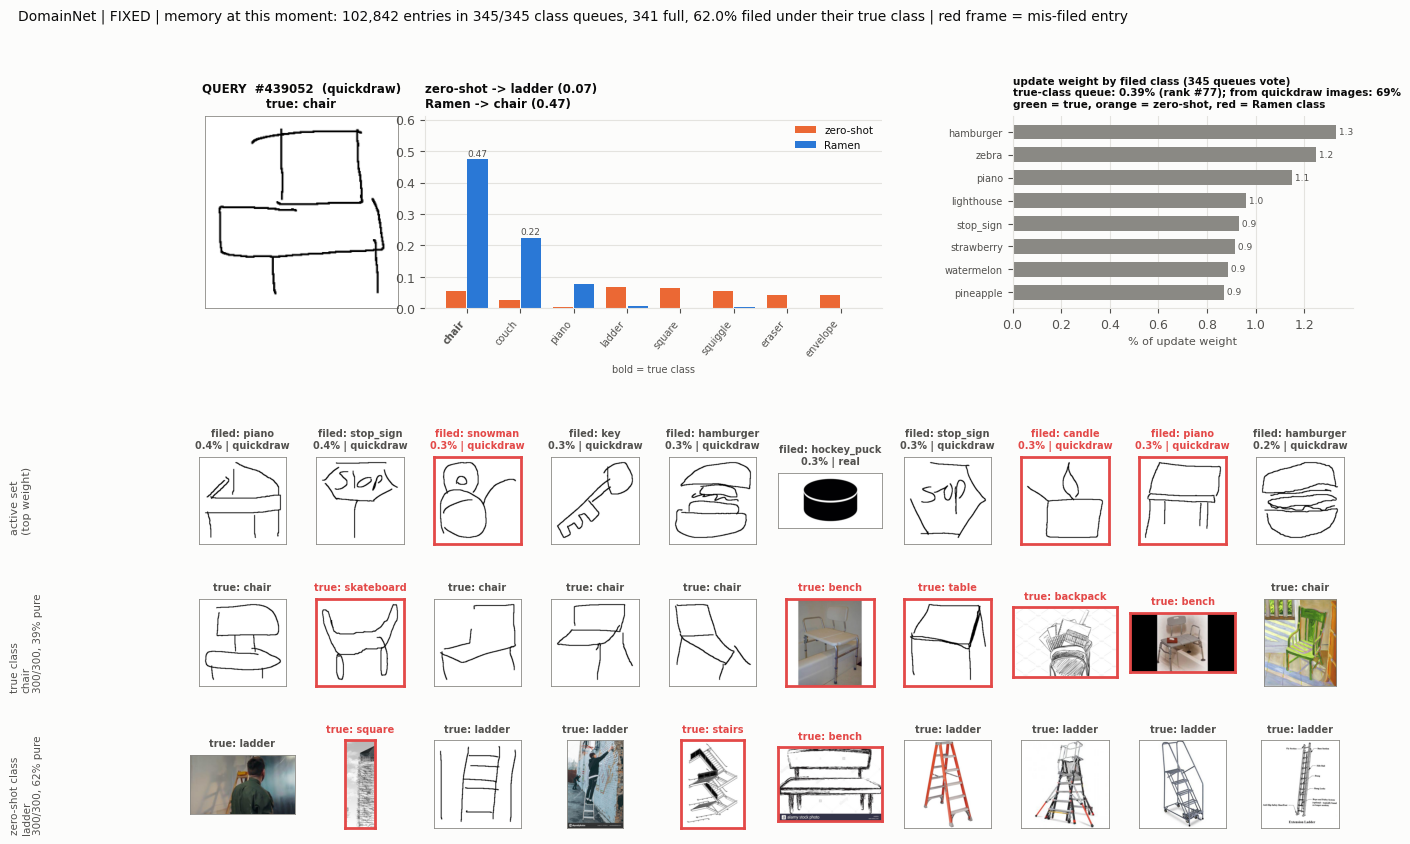

In [9]:
ex.show(fixed.position.iloc[2], states);

**Fixed examples (quickdraw):** donut (circle -> donut, 0.14 -> 0.57), mouth (nose -> mouth, 0.07 -> 0.24), chair (ladder -> chair, 0.06 -> 0.47). About 70% of the update weight comes from other quickdraw sketches, mostly of unrelated classes (piano, stop sign, key, hamburger). For mouth, the true-class queue still ranks #2 of 345. The memory teaches "how to read a sketch", and with it CLIP's text head moves off the generic shape attractors (circle, squiggle, ladder) that zero-shot CLIP picks for line drawings. The zero-shot-class queues are full of mis-filed sketches (nose: 20% pure, mostly sketches of other things).

## 5. Examples where Ramen fails (broken, from the domain with the lowest fixed / broken ratio)

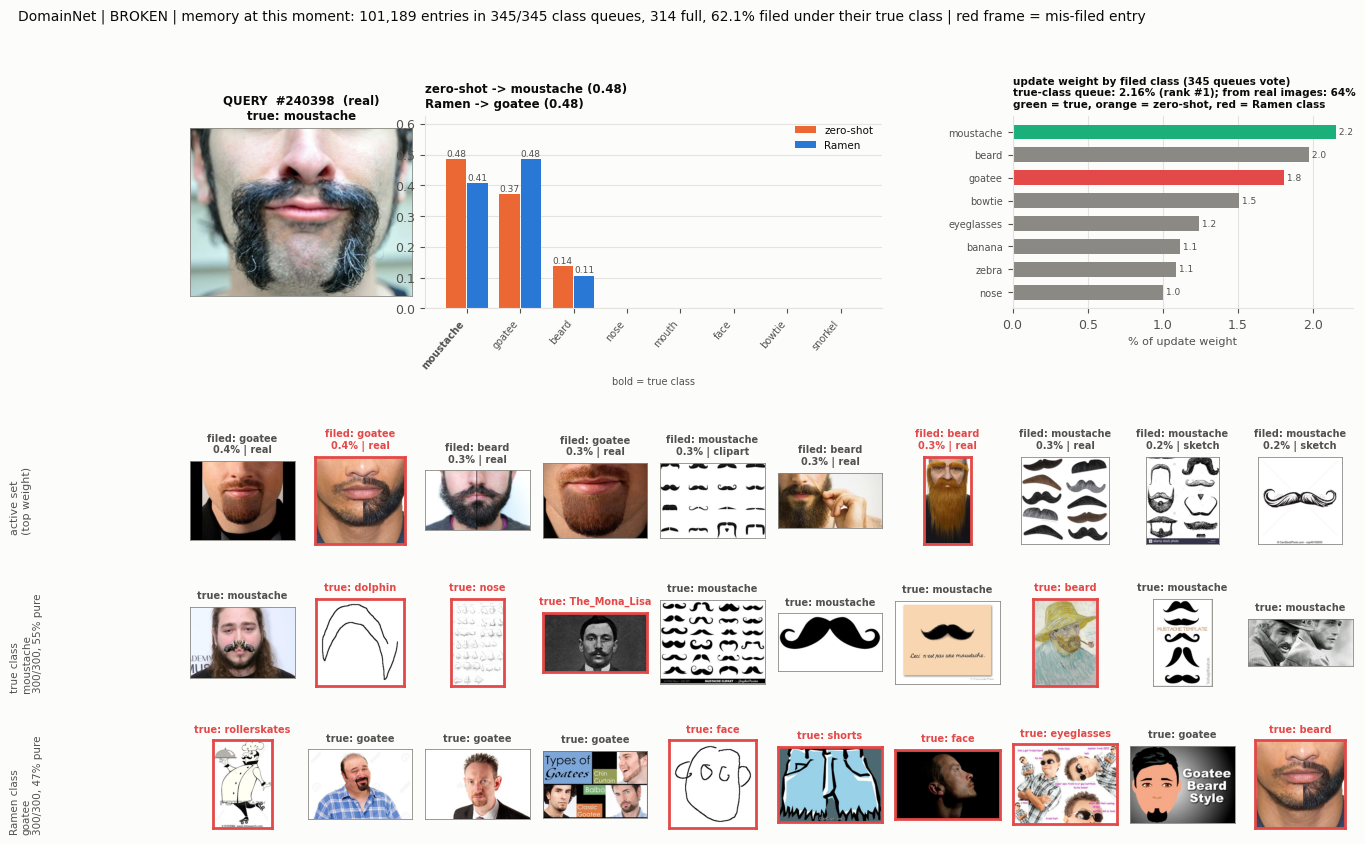

In [10]:
ex.show(broken.position.iloc[0], states);

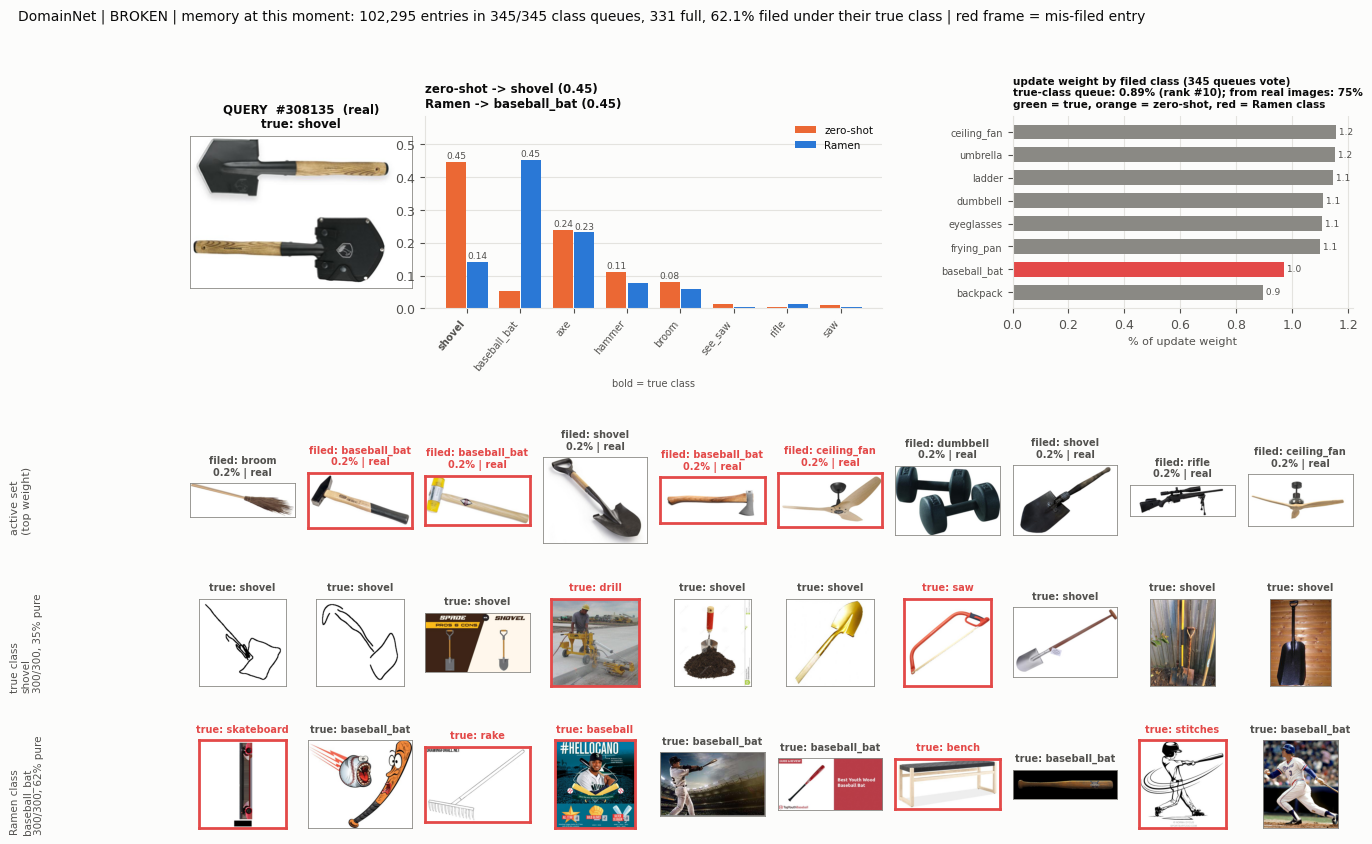

In [11]:
ex.show(broken.position.iloc[1], states);

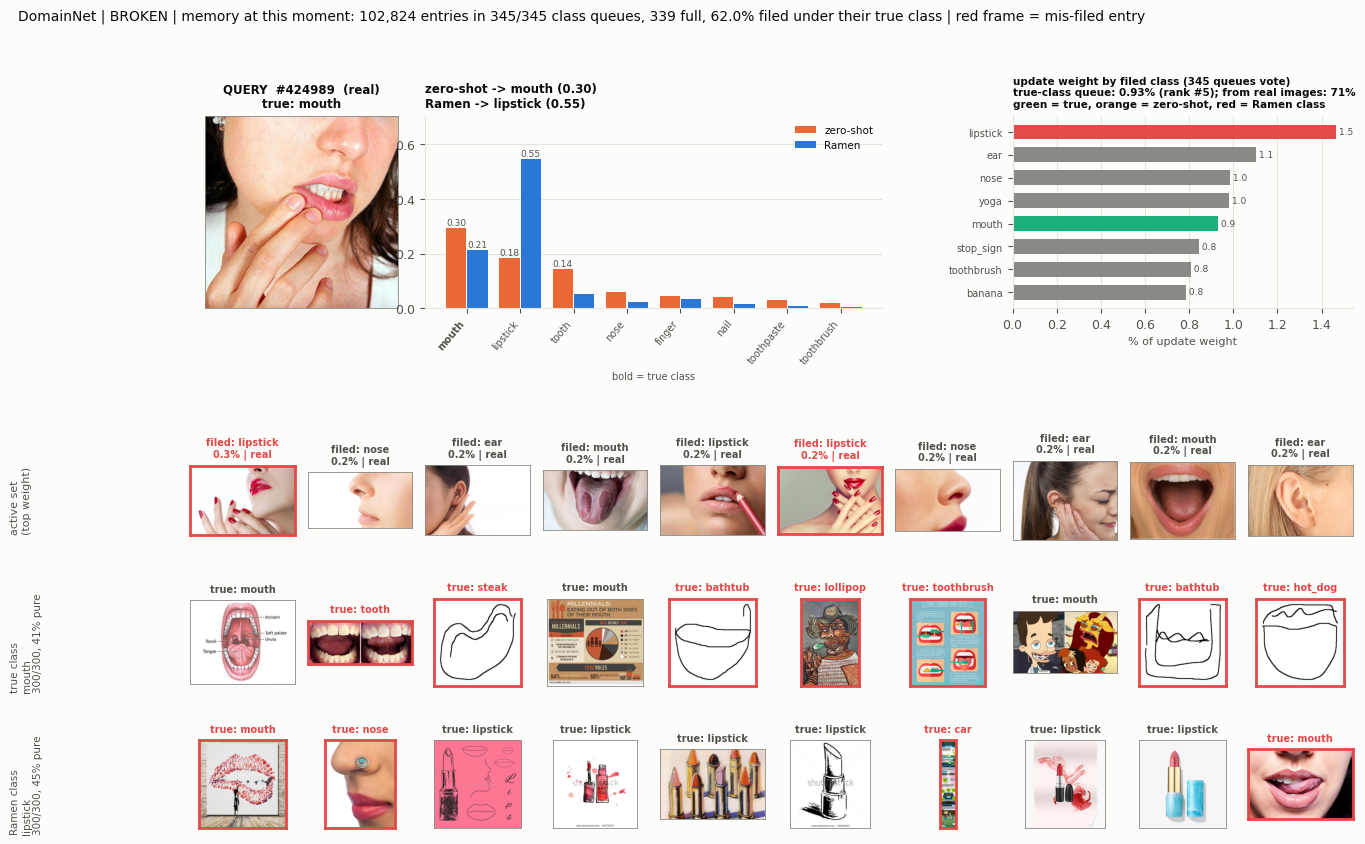

In [12]:
ex.show(broken.position.iloc[2], states);

**Broken examples (real):** moustache -> goatee, shovel -> baseball bat, mouth -> lipstick. All three are again near-ties pushed to the neighbouring class. Here, unlike on ImageNet-C, the active set is visibly class-related, and that is what breaks it:
- for the shovel, several retrieved entries are hammers and axes **mis-filed under baseball_bat** (long wooden handles);
- for the mouth, the nearest neighbours are lip and lipstick photos, and the lipstick queue gets the single largest class weight (1.5%, against 0.9% for mouth at rank 5).

The real domain has the highest zero-shot accuracy (82%), so its few errors are fine-grained, and a step toward the local neighbourhood can land on the adjacent class.

## Summary (DomainNet, seed 0)
- Ramen helps on all 6 domains: most on quickdraw (+4.2, 3.2 fixed per broken), least on real (+0.15, 1.1 fixed per broken, nearly break-even).
- As on ImageNet-C, the gain is a **domain-level** correction: 60-70% of a quickdraw query's update comes from other sketches, mostly of unrelated classes.
- **Failures are low-margin zero-shot hits on easy, photo-like images**, pushed to a semantic neighbour. With beta 5 the active set is local enough that mis-filed neighbours (hammers filed as baseball_bat) and neighbouring-class queues (lipstick) can steer the step.
- **Late in the stream the memory is frozen** (fp16 priority saturation; 95%+ of queues full). The images shown are what Ramen has been retrieving from since roughly sample 65k. The query itself is never in the memory, so the 'self' term Ramen relies on early on is absent.
- Caveat: an entry's weight is its share of the weighted gradient sum, but Ramen takes the **sign** of that sum (SignSGD). The weights say which entries count, not how much each one moves the prediction.